# Learning physiology

Membrane time constants, thresholds and synaptic kinetics differ between cell types and
are rarely all measured. Every network takes a `learn=` argument that makes such
parameters trainable, per cell type or synapse type.

Here a current-based network learns the membrane time constants and thresholds of its
two cell types from a teacher's spikes, with an ordinary PyTorch training loop. The
network is feedforward with fixed weights, so only the physiology is fitted.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch

import wiretorch as wt
from wiretorch import visualization as viz

viz.use_theme()  # the docs' plot style, light and dark
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
rng = np.random.default_rng(0)

## The networks

Current-based neurons use natural units by default (threshold 1, reset and rest at 0)
and integrate $\tau_m \dot v = -v + \sum_s \sigma_s I_s$, where each synapse type's current
jumps by the weight on an input spike and decays with $\tau_s$ ({doc}`../concepts/neuron-models`).
200 neurons of two types, which here differ only in their physiology, receive 100
Poisson inputs through fixed weights.

In [2]:
N, N_IN = 200, 100
types = (rng.random(N) < 0.2).astype(int)  # 0: "E", 1: "I"
w = (rng.random((N_IN, N)) < 0.2) * rng.lognormal(np.log(0.5), 0.5, (N_IN, N))


def network(tau_E, tau_I, theta_E, theta_I, learn=None):
    return wt.FeedforwardCurrentLIFNetwork(
        dt=1.0,
        projections={
            ("input", "E"): wt.FrozenProjection(w[:, types == 0].astype(np.float32)),
            ("input", "I"): wt.FrozenProjection(w[:, types == 1].astype(np.float32)),
        },
        cell_type_indices=types,
        cell_type_indices_FF=np.zeros(N_IN, dtype=int),
        cell_params=[
            dict(name="E", cell_id=0, tau_mem=tau_E, theta=theta_E),
            dict(name="I", cell_id=1, tau_mem=tau_I, theta=theta_I),
        ],
        cell_params_FF=[dict(name="input", cell_id=0)],
        synapse_params_FF=[
            dict(name="exc", synapse_id=0, cell_id=0, tau_syn=5.0, type="excitatory")
        ],
        surrgrad_scale=5.0,
        batch_size=8,
        learn=learn,
    ).to(device)


teacher = network(tau_E=20.0, tau_I=10.0, theta_E=1.0, theta_I=1.0)
x = (torch.rand(8, 2000, N_IN, device=device) < 20.0 / 1000).float()  # 2 s at 20 Hz
with torch.no_grad():
    target = teacher(x)
print(f"teacher: {target.mean().item() * 1000:.1f} Hz")

teacher: 33.3 Hz


The student has the teacher's weights but the wrong physiology, and learns `tau_mem` and
`theta` for both cell types. Parameters not named in `learn` stay fixed. The learnt
values are in `student.cell_parameters`, with time constants stored as logarithms so
that they stay positive:

In [3]:
student = network(tau_E=35.0, tau_I=5.0, theta_E=1.3, theta_I=0.8,
                  learn={"tau_mem": True, "theta": True})  # fmt: skip
print([name for name, _ in student.named_parameters()])
print("tau_mem:", student.cell_parameters.value("tau_mem").tolist())

['cell_parameters.log_tau_mem', 'cell_parameters.theta']
tau_mem: [35.000003814697266, 5.000000476837158]


## Training

The loop runs the input in 500 ms chunks with the state carried over, compares the
output with the teacher's spikes using the van Rossum distance, and steps the
optimiser. Gradients reach the physiology through the surrogate derivative of the
spikes.

<Figure size 1100x352 with 2 Axes>
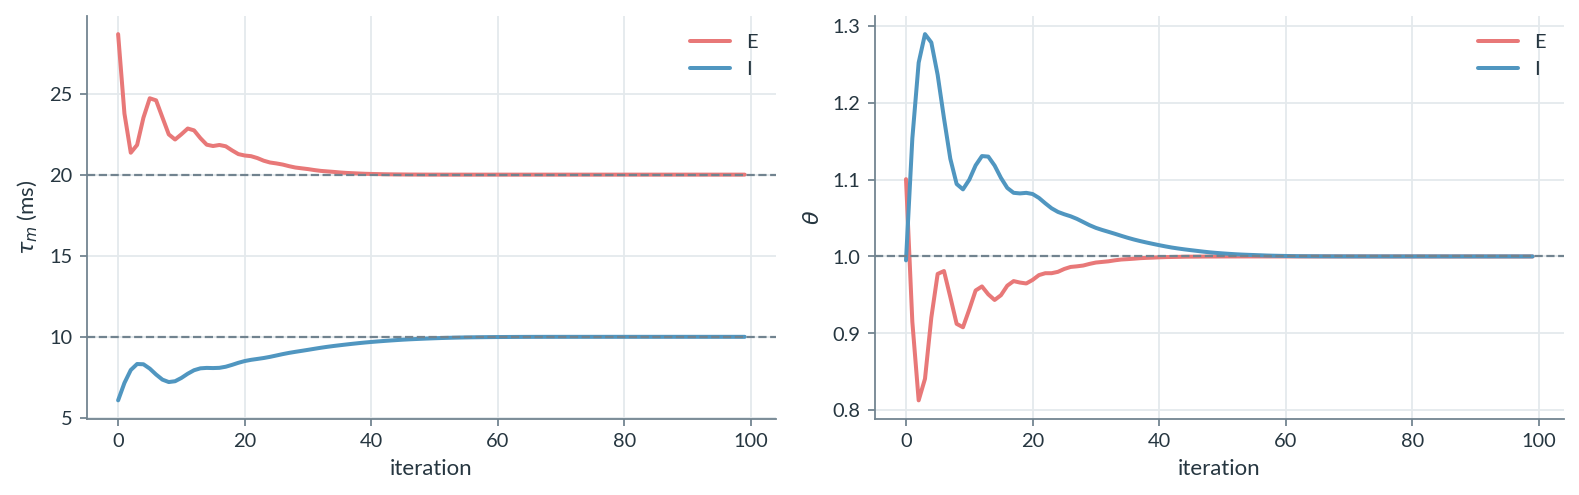
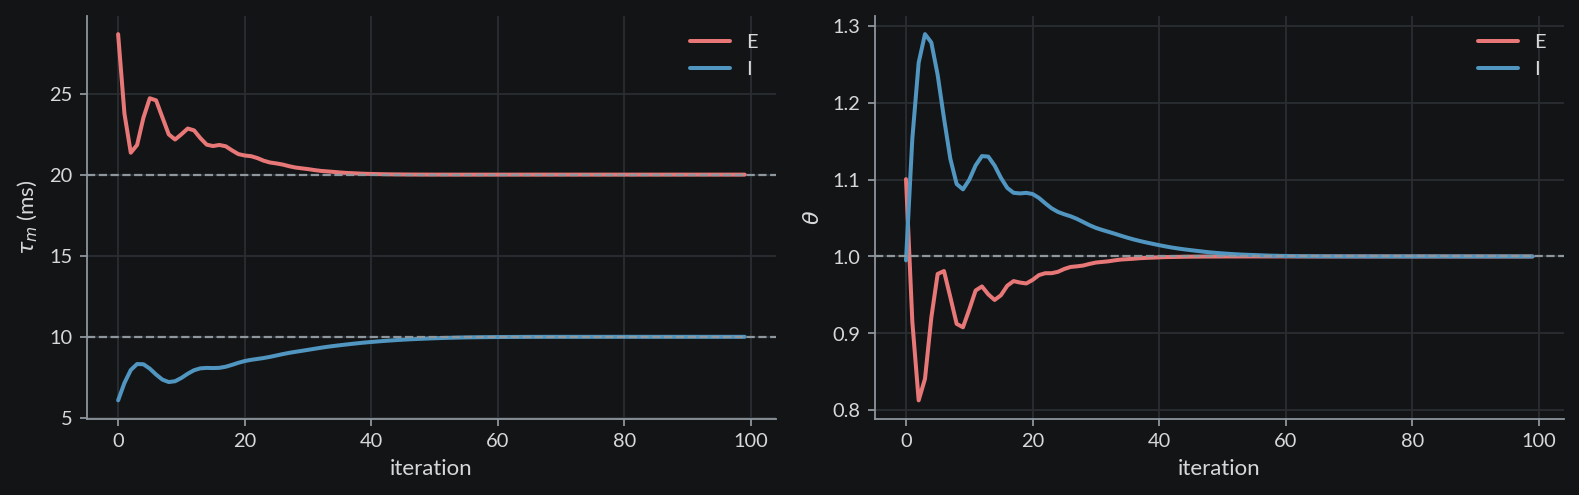

learnt tau_mem: [20. 10.]  theta: [1. 1.]


In [4]:
optimiser = torch.optim.Adam(student.parameters(), lr=0.05)
loss_fn = wt.VanRossumLoss(5.0, 20.0, dt=1.0, window_size=500, device=device)
history = []
for iteration in range(100):
    student.reset_state(), loss_fn.reset_state()
    for c in range(0, x.shape[1], 500):
        loss = loss_fn(student(x[:, c : c + 500]), target[:, c : c + 500])
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
    values = student.cell_parameters
    history.append((values.value("tau_mem").tolist(), values.value("theta").tolist()))

tau, theta = (np.array(h) for h in zip(*history))
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.2))
for ax in (a, b):
    ax.set_prop_cycle(color=[viz.theme.EXCITATORY, viz.theme.INHIBITORY])
(
    a.plot(tau, label=["E", "I"]),
    a.axhline(20, color=viz.theme.MUTED, ls="--", lw=1),
    a.axhline(10, color=viz.theme.MUTED, ls="--", lw=1),
)
a.set_xlabel("iteration"), a.set_ylabel(r"$\tau_m$ (ms)"), a.legend()
b.plot(theta, label=["E", "I"]), b.axhline(1, color=viz.theme.MUTED, ls="--", lw=1)
b.set_xlabel("iteration"), b.set_ylabel(r"$\theta$"), b.legend()
plt.tight_layout(), plt.show()
print("learnt tau_mem:", tau[-1].round(2), " theta:", theta[-1].round(3))

## What can be learnt

| Family | Per cell type | Per synapse type |
|---|---|---|
| Conductance-based | `tau_mem`, `theta`, `U_reset`, `E_L`, `g_L` | `tau_rise`, `tau_decay`, `E_syn`, `g_bar` |
| Current-based | `tau_mem`, `theta`, `U_reset`, `U_rest`, `R` | `tau_syn` |
| Rate | `tau_mem`, `theta`, `gain` | `tau_syn` |

To learn a parameter for only some types, name them, as in
`learn={"theta": ["E"], "tau_syn": ["exc"]}`. Combined with trainable projections, this
fits connectivity and physiology together.